Dataset loaded successfully!
Rows: 11110


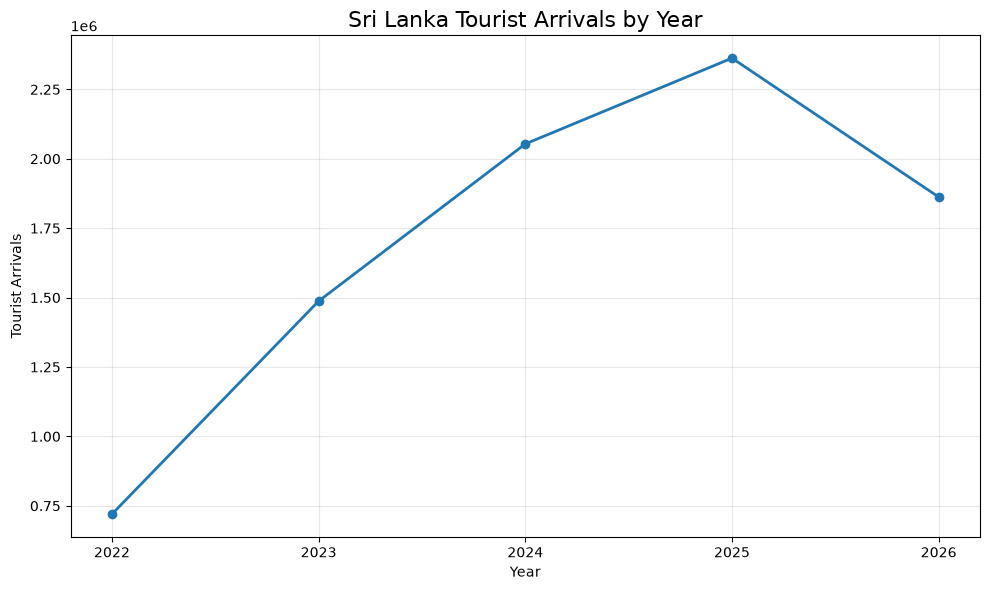

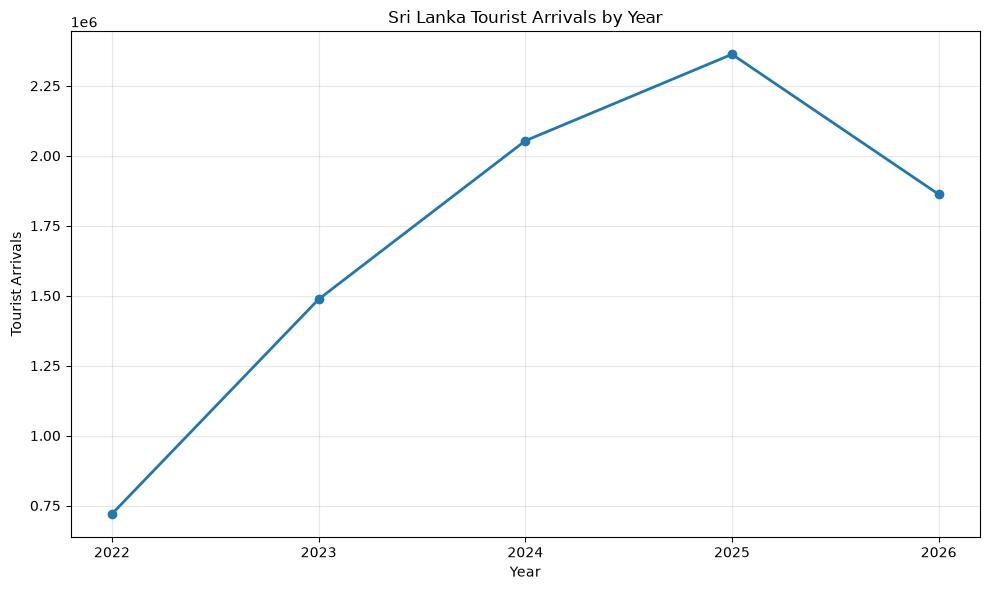

Chart saved successfully.


In [1]:
# ============================================================
# SRI LANKA TOURISM - VISUALIZATION
# MATPLOTLIB
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD CLEAN DATA
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

input_file = PROCESSED_DIR / "tourism_arrivals_clean.csv"

tourism = pd.read_csv(input_file)

tourism["Date"] = pd.to_datetime(tourism["Date"])

print("Dataset loaded successfully!")
print("Rows:", len(tourism))


# ------------------------------------------------------------
# 2. PREPARE YEARLY DATA
# ------------------------------------------------------------

yearly = (
    tourism.groupby("Year", as_index=False)["Arrivals"]
    .sum(min_count=1)
)


# ------------------------------------------------------------
# 3. YEARLY ARRIVALS LINE CHART
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    yearly["Year"],
    yearly["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Sri Lanka Tourist Arrivals by Year",
    fontsize=16
)

plt.xlabel("Year")
plt.ylabel("Tourist Arrivals")

plt.xticks(yearly["Year"])

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 4. SAVE CHART
# ------------------------------------------------------------

output_dir = PROJECT_ROOT / "visualizations" / "matplotlib"

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

plt.figure(figsize=(10, 6))

plt.plot(
    yearly["Year"],
    yearly["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title("Sri Lanka Tourist Arrivals by Year")
plt.xlabel("Year")
plt.ylabel("Tourist Arrivals")
plt.xticks(yearly["Year"])
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    output_dir / "01_yearly_tourist_arrivals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully.")

In [2]:
# ============================================================
# PROJECT 01 - SRI LANKA TOURISM ANALYTICS
# NOTEBOOK 04 - COMPLETE VISUALIZATION
# ============================================================
#
# Creates:
#   MATPLOTLIB
#   1. Yearly tourist arrivals
#   2. Jan-Oct comparable yearly arrivals
#   3. Monthly tourist arrivals trend
#   4. Average monthly seasonality
#   5. Top 15 source countries
#   6. Top 10 country share
#
#   SEABORN
#   7. Year-Month heatmap
#   8. Top 15 countries heatmap
#   9. Monthly distribution boxplot
#   10. Top 10 countries by year
#
#   PLOTLY
#   11. Interactive monthly trend
#   12. Interactive top 15 countries
#   13. Interactive yearly comparison
#   14. Interactive country-year trend
#
# All outputs are automatically saved.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path


# ------------------------------------------------------------
# 2. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MATPLOTLIB_DIR = PROJECT_ROOT / "visualizations" / "matplotlib"
SEABORN_DIR = PROJECT_ROOT / "visualizations" / "seaborn"
PLOTLY_DIR = PROJECT_ROOT / "visualizations" / "plotly"

MATPLOTLIB_DIR.mkdir(parents=True, exist_ok=True)
SEABORN_DIR.mkdir(parents=True, exist_ok=True)
PLOTLY_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 3. LOAD CLEAN DATA
# ------------------------------------------------------------

input_file = PROCESSED_DIR / "tourism_arrivals_clean.csv"

tourism = pd.read_csv(input_file)

tourism["Date"] = pd.to_datetime(tourism["Date"])

tourism["Year"] = tourism["Year"].astype(int)

tourism["Month_Number"] = tourism["Month_Number"].astype(int)

tourism["Arrivals"] = pd.to_numeric(
    tourism["Arrivals"],
    errors="coerce"
)

# Use standardized country name where available
if "Country_Standardized" in tourism.columns:
    tourism["Country_Display"] = (
        tourism["Country_Standardized"]
        .fillna(tourism["Country"])
        .astype(str)
        .str.strip()
    )
else:
    tourism["Country_Display"] = (
        tourism["Country"]
        .astype(str)
        .str.strip()
    )


print("=" * 70)
print("SRI LANKA TOURISM - COMPLETE VISUALIZATION")
print("=" * 70)

print("\nDataset loaded successfully!")
print("Rows:", len(tourism))
print("Countries:", tourism["Country_Display"].nunique())
print("Years:", sorted(tourism["Year"].unique()))
print(
    "Date range:",
    tourism["Date"].min().date(),
    "to",
    tourism["Date"].max().date()
)

print("\n2026 contains Jan-Oct only.")
print("Full-year comparisons should therefore exclude 2026.")


# ============================================================
# MATPLOTLIB VISUALIZATIONS
# ============================================================


# ------------------------------------------------------------
# 4. YEARLY TOURIST ARRIVALS
# ------------------------------------------------------------

yearly = (
    tourism.groupby("Year", as_index=False)["Arrivals"]
    .sum(min_count=1)
)

plt.figure(figsize=(10, 6))

plt.plot(
    yearly["Year"],
    yearly["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Sri Lanka Tourist Arrivals by Year",
    fontsize=16
)

plt.xlabel("Year")
plt.ylabel("Tourist Arrivals")

plt.xticks(yearly["Year"])

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "01_yearly_tourist_arrivals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 5. JANUARY-OCTOBER COMPARISON
# ------------------------------------------------------------

jan_oct = (
    tourism[tourism["Month_Number"] <= 10]
    .groupby("Year", as_index=False)["Arrivals"]
    .sum(min_count=1)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    jan_oct["Year"].astype(str),
    jan_oct["Arrivals"]
)

plt.title(
    "Sri Lanka Tourist Arrivals - January to October Comparison",
    fontsize=15
)

plt.xlabel("Year")

plt.ylabel("Tourist Arrivals")

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(bars, jan_oct["Arrivals"]):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "02_jan_oct_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 6. MONTHLY TOURIST ARRIVALS TREND
# ------------------------------------------------------------

monthly = (
    tourism.groupby(
        ["Date", "Year", "Month_Number"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

plt.figure(figsize=(14, 7))

plt.plot(
    monthly["Date"],
    monthly["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Tourist Arrivals in Sri Lanka",
    fontsize=16
)

plt.xlabel("Month")

plt.ylabel("Tourist Arrivals")

plt.grid(
    True,
    alpha=0.3
)

plt.xticks(
    monthly["Date"],
    monthly["Date"].dt.strftime("%b-%Y"),
    rotation=45
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "03_monthly_tourist_arrivals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 7. SEASONALITY - AVERAGE ARRIVALS BY MONTH
# ------------------------------------------------------------

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

seasonality = (
    tourism.groupby(
        ["Month_Number", "Month"],
        as_index=False
    )["Arrivals"]
    .mean()
    .sort_values("Month_Number")
)

plt.figure(figsize=(12, 6))

plt.plot(
    seasonality["Month"],
    seasonality["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Average Monthly Tourist Arrivals - Seasonality",
    fontsize=16
)

plt.xlabel("Month")

plt.ylabel("Average Tourist Arrivals")

plt.xticks(
    rotation=45
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "04_tourism_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 8. TOP 15 SOURCE COUNTRIES
# ------------------------------------------------------------

country_totals = (
    tourism.groupby(
        "Country_Display",
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
    .sort_values(
        "Arrivals",
        ascending=False
    )
)

top15 = country_totals.head(15).sort_values(
    "Arrivals"
)

plt.figure(figsize=(11, 8))

plt.barh(
    top15["Country_Display"],
    top15["Arrivals"]
)

plt.title(
    "Top 15 Tourist Source Countries",
    fontsize=16
)

plt.xlabel("Total Tourist Arrivals")

plt.ylabel("Country")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "05_top_15_source_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 9. TOP 10 COUNTRY SHARE
# ------------------------------------------------------------

top10 = country_totals.head(10).copy()

total_arrivals = country_totals["Arrivals"].sum()

top10["Share"] = (
    top10["Arrivals"] /
    total_arrivals *
    100
)

plt.figure(figsize=(12, 7))

plt.bar(
    top10["Country_Display"],
    top10["Share"]
)

plt.title(
    "Top 10 Source Countries - Share of Total Arrivals",
    fontsize=15
)

plt.xlabel("Country")

plt.ylabel("Share of Total Arrivals (%)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "06_top_10_country_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SEABORN VISUALIZATIONS
# ============================================================


# ------------------------------------------------------------
# 10. YEAR-MONTH HEATMAP
# ------------------------------------------------------------

heatmap_data = (
    monthly
    .pivot(
        index="Year",
        columns="Month_Number",
        values="Arrivals"
    )
)

heatmap_data = heatmap_data.reindex(
    columns=range(1, 13)
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Monthly Tourist Arrivals Heatmap",
    fontsize=16
)

plt.xlabel("Month Number")

plt.ylabel("Year")

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "07_year_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 11. TOP 15 COUNTRIES HEATMAP
# ------------------------------------------------------------

top15_names = country_totals.head(15)["Country_Display"]

country_year = (
    tourism[
        tourism["Country_Display"].isin(top15_names)
    ]
    .groupby(
        ["Country_Display", "Year"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

country_year_heatmap = (
    country_year
    .pivot(
        index="Country_Display",
        columns="Year",
        values="Arrivals"
    )
)

country_year_heatmap = country_year_heatmap.reindex(
    top15_names
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    country_year_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Top 15 Tourist Source Countries by Year",
    fontsize=16
)

plt.xlabel("Year")

plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "08_top_15_country_year_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 12. MONTHLY DISTRIBUTION BOXPLOT
# ------------------------------------------------------------

monthly_box = (
    tourism.groupby(
        ["Year", "Month"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

monthly_box["Month"] = pd.Categorical(
    monthly_box["Month"],
    categories=month_order,
    ordered=True
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=monthly_box,
    x="Month",
    y="Arrivals"
)

plt.title(
    "Distribution of Monthly Tourist Arrivals",
    fontsize=16
)

plt.xlabel("Month")

plt.ylabel("Tourist Arrivals")

plt.xticks(
    rotation=45
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "09_monthly_distribution_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 13. TOP 10 COUNTRIES BY YEAR
# ------------------------------------------------------------

top10_names = country_totals.head(10)["Country_Display"]

top10_year = (
    tourism[
        tourism["Country_Display"].isin(top10_names)
    ]
    .groupby(
        ["Year", "Country_Display"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=top10_year,
    x="Year",
    y="Arrivals",
    hue="Country_Display"
)

plt.title(
    "Top 10 Tourist Source Countries by Year",
    fontsize=16
)

plt.xlabel("Year")

plt.ylabel("Tourist Arrivals")

plt.legend(
    title="Country",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "10_top_10_countries_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOTLY INTERACTIVE VISUALIZATIONS
# ============================================================


# ------------------------------------------------------------
# 14. INTERACTIVE MONTHLY TREND
# ------------------------------------------------------------

fig = px.line(
    monthly,
    x="Date",
    y="Arrivals",
    markers=True,
    title="Interactive Monthly Tourist Arrivals - Sri Lanka",
    labels={
        "Date": "Month",
        "Arrivals": "Tourist Arrivals"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.write_html(
    PLOTLY_DIR / "11_interactive_monthly_trend.html"
)

fig.show()


# ------------------------------------------------------------
# 15. INTERACTIVE TOP 15 COUNTRIES
# ------------------------------------------------------------

plotly_top15 = (
    country_totals
    .head(15)
    .sort_values("Arrivals")
)

fig = px.bar(
    plotly_top15,
    x="Arrivals",
    y="Country_Display",
    orientation="h",
    title="Interactive Top 15 Tourist Source Countries",
    labels={
        "Arrivals": "Total Tourist Arrivals",
        "Country_Display": "Country"
    }
)

fig.update_layout(
    template="plotly_white"
)

fig.write_html(
    PLOTLY_DIR / "12_interactive_top_15_countries.html"
)

fig.show()


# ------------------------------------------------------------
# 16. INTERACTIVE YEARLY COMPARISON
# ------------------------------------------------------------

fig = px.bar(
    yearly,
    x="Year",
    y="Arrivals",
    text="Arrivals",
    title="Interactive Sri Lanka Tourist Arrivals by Year",
    labels={
        "Year": "Year",
        "Arrivals": "Tourist Arrivals"
    }
)

fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white"
)

fig.write_html(
    PLOTLY_DIR / "13_interactive_yearly_arrivals.html"
)

fig.show()


# ------------------------------------------------------------
# 17. INTERACTIVE COUNTRY-YEAR TREND
# ------------------------------------------------------------

fig = px.line(
    country_year,
    x="Year",
    y="Arrivals",
    color="Country_Display",
    markers=True,
    title="Interactive Tourist Arrivals by Major Source Country",
    labels={
        "Year": "Year",
        "Arrivals": "Tourist Arrivals",
        "Country_Display": "Country"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.write_html(
    PLOTLY_DIR / "14_interactive_country_year_trend.html"
)

fig.show()


# ============================================================
# 18. FINAL VISUALIZATION REPORT
# ============================================================

print("\n")
print("=" * 70)
print("VISUALIZATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nMatplotlib charts created:")
print("  01_yearly_tourist_arrivals.png")
print("  02_jan_oct_comparison.png")
print("  03_monthly_tourist_arrivals.png")
print("  04_tourism_seasonality.png")
print("  05_top_15_source_countries.png")
print("  06_top_10_country_share.png")

print("\nSeaborn charts created:")
print("  07_year_month_heatmap.png")
print("  08_top_15_country_year_heatmap.png")
print("  09_monthly_distribution_boxplot.png")
print("  10_top_10_countries_by_year.png")

print("\nPlotly interactive charts created:")
print("  11_interactive_monthly_trend.html")
print("  12_interactive_top_15_countries.html")
print("  13_interactive_yearly_arrivals.html")
print("  14_interactive_country_year_trend.html")

print("\nOutput folders:")
print("  ", MATPLOTLIB_DIR)
print("  ", SEABORN_DIR)
print("  ", PLOTLY_DIR)

print("\nImportant:")
print("2026 data covers January-October only.")
print("Use the January-October comparison for fair year-to-year comparison.")

print("\nTotal visualization files created: 14")
print("=" * 70)

KeyError: 'Country'

In [3]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
file = PROJECT_ROOT / "data" / "processed" / "tourism_arrivals_clean.csv"

tourism = pd.read_csv(file)

print(tourism.columns.tolist())

['Country_Raw', 'Country_Standardized', 'Year', 'Month_Number', 'Month', 'Date', 'Arrivals']


SRI LANKA TOURISM - COMPLETE VISUALIZATION

Dataset loaded successfully!

Rows: 11110
Columns: ['Country_Raw', 'Country_Standardized', 'Year', 'Month_Number', 'Month', 'Date', 'Arrivals', 'Country_Display']
Unique countries: 229
Years: [2022, 2023, 2024, 2025, 2026]
Date range: 2022-01-01 to 2026-10-01

2026 contains January-October only.

Yearly arrivals:
   Year   Arrivals
0  2022   719978.0
1  2023  1487303.0
2  2024  2053465.0
3  2025  2362521.0
4  2026  1862304.0

January-October comparison:
   Year   Arrivals
0  2022   568258.0
1  2023  1125455.0
2  2024  1620715.0
3  2025  1890687.0
4  2026  1862304.0


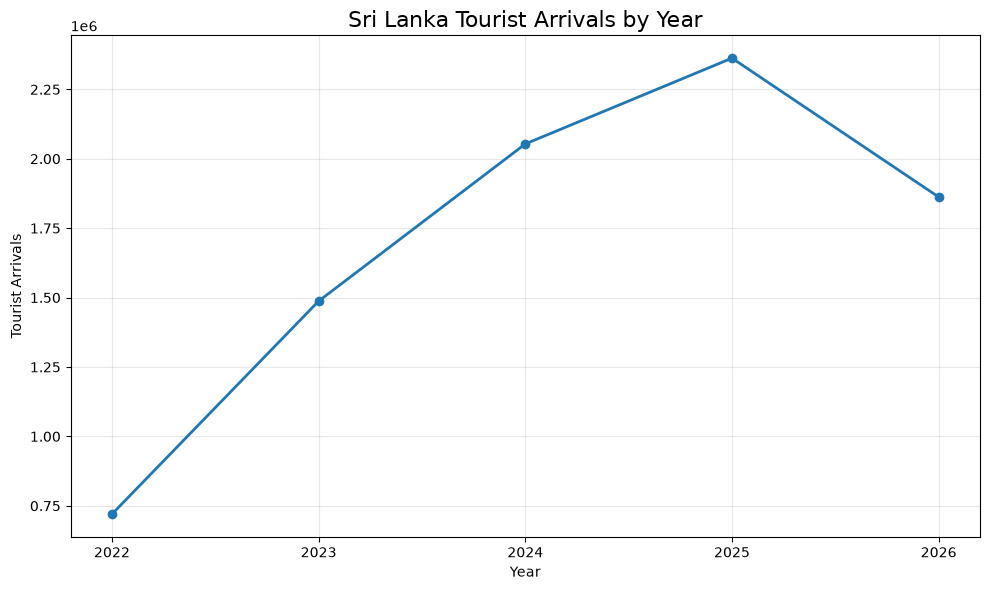

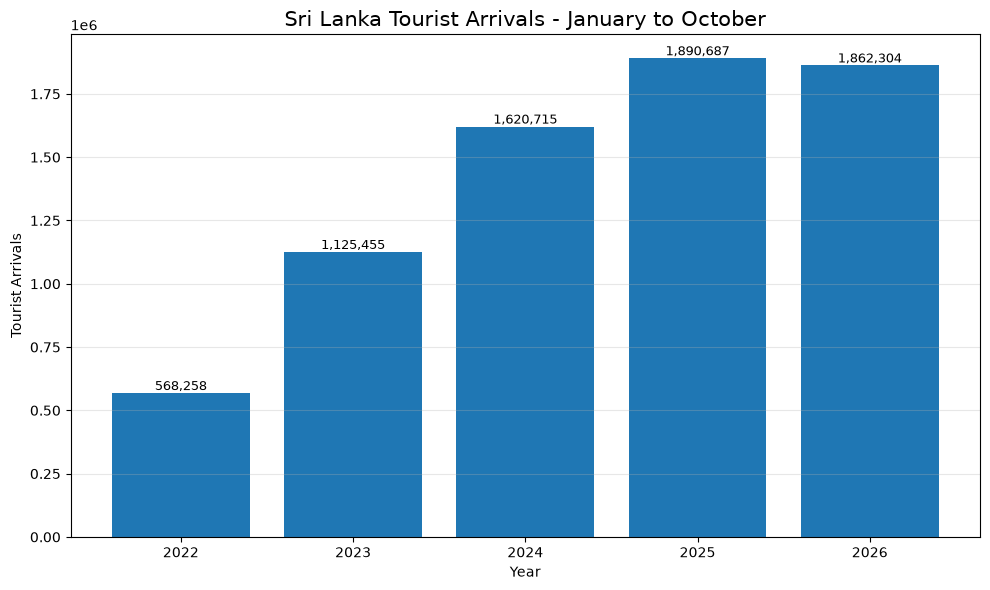

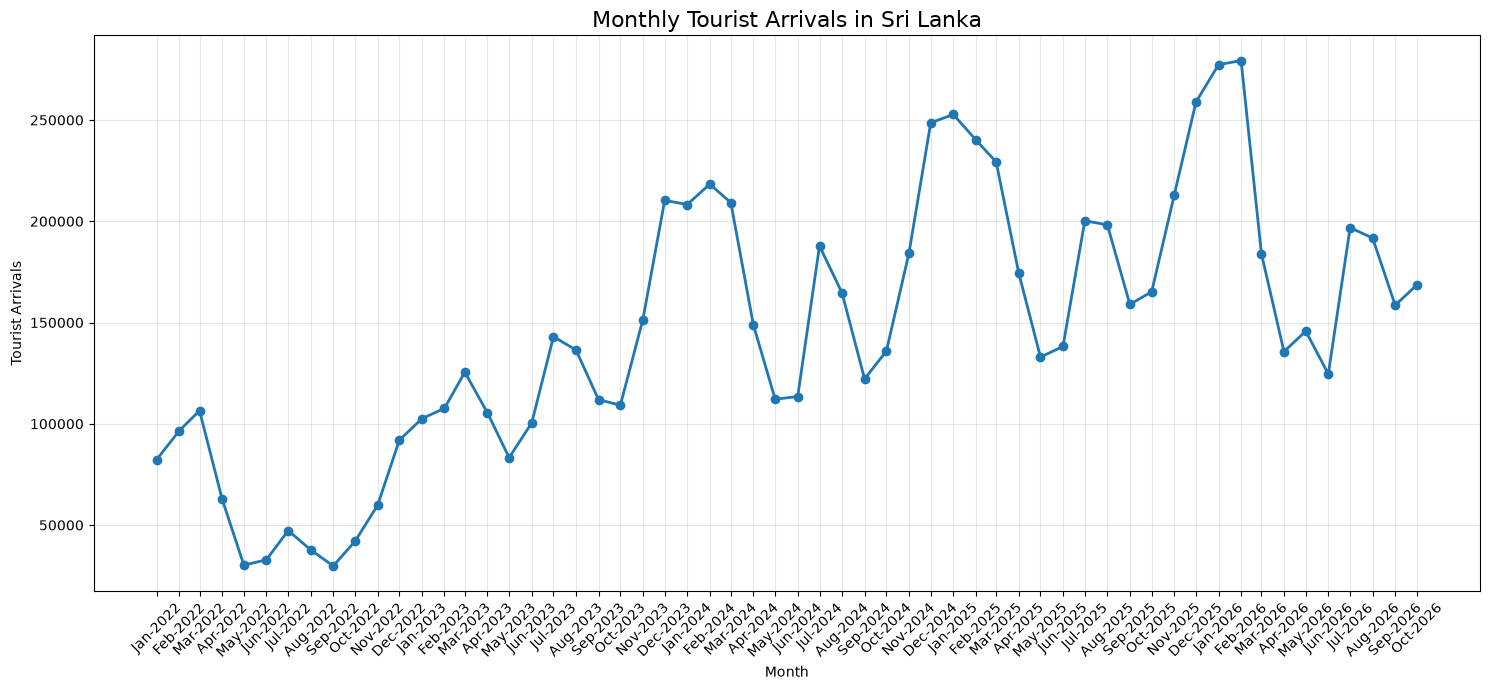

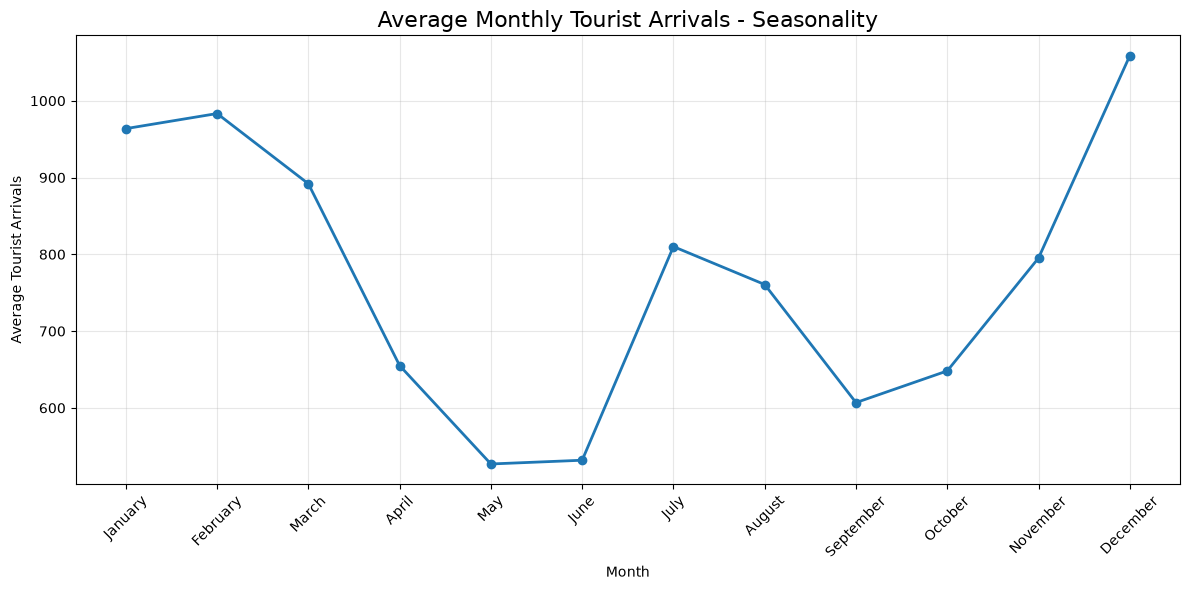

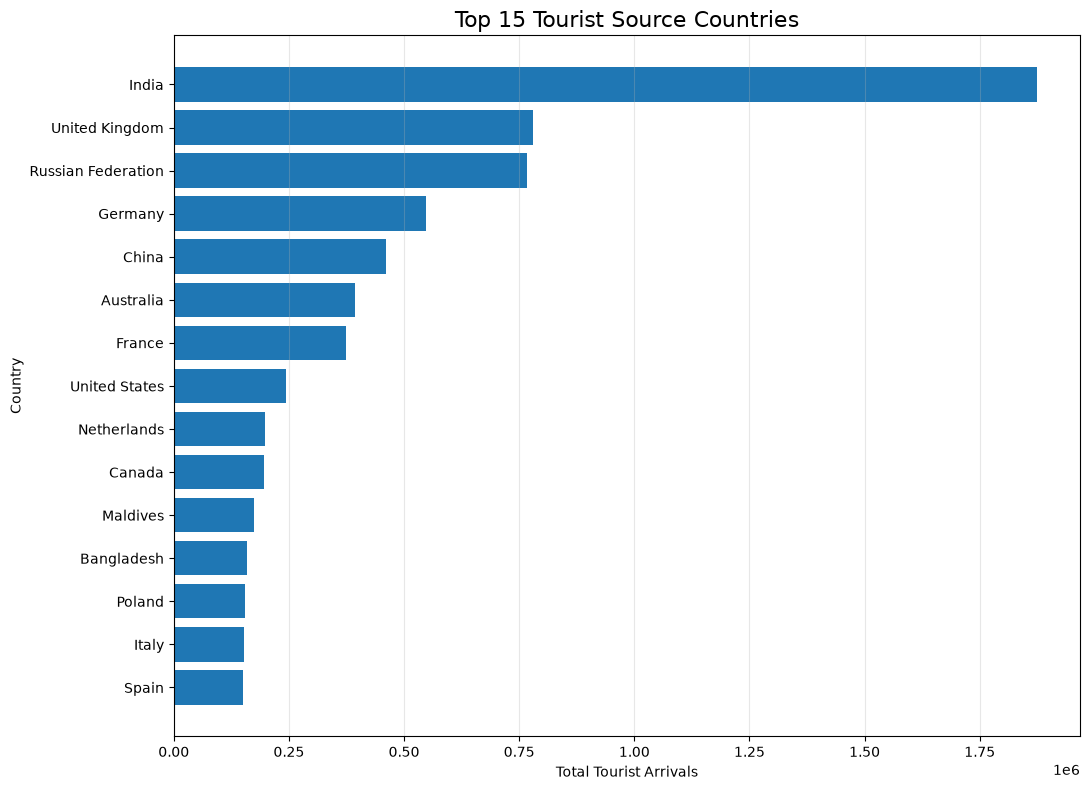

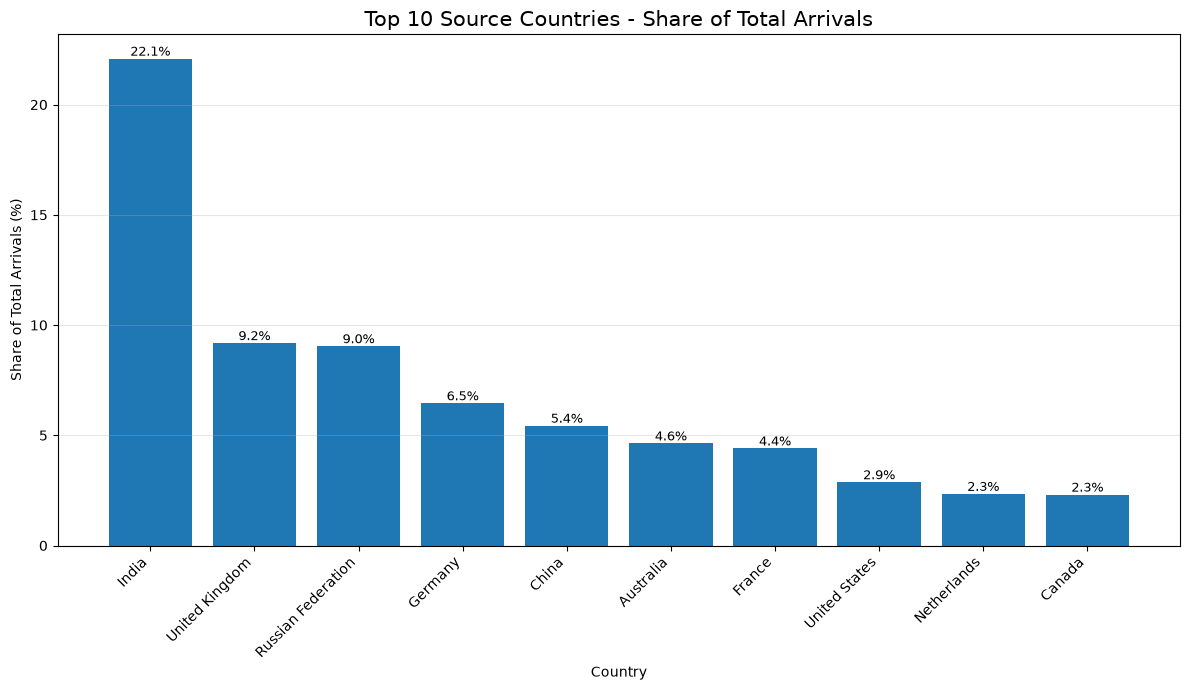

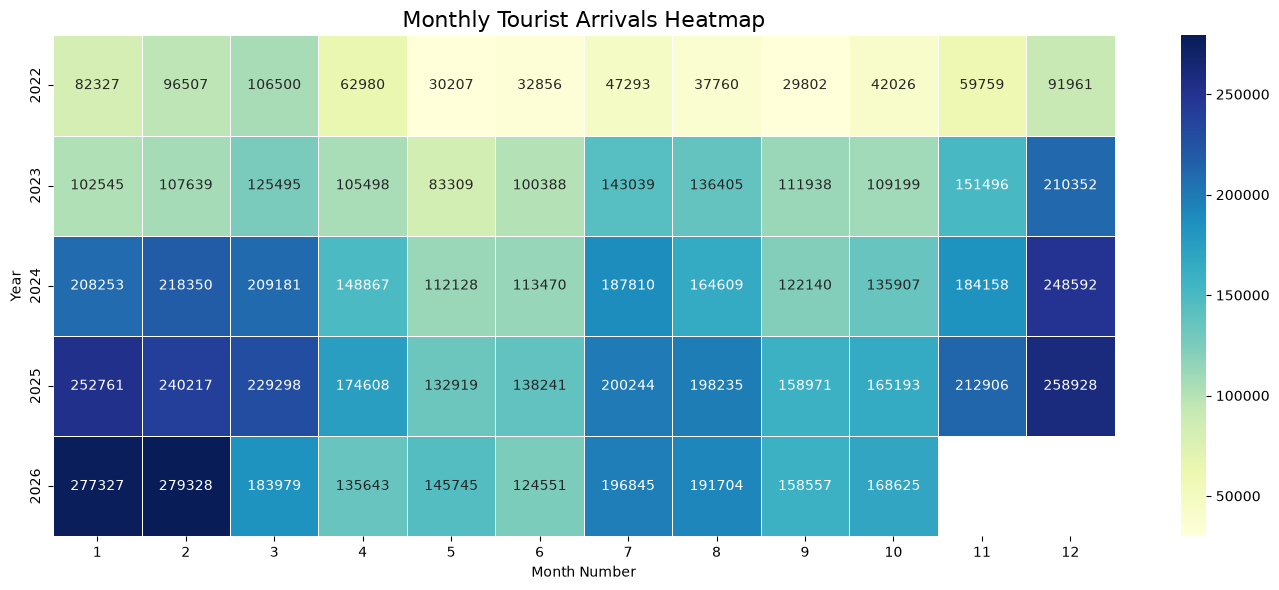

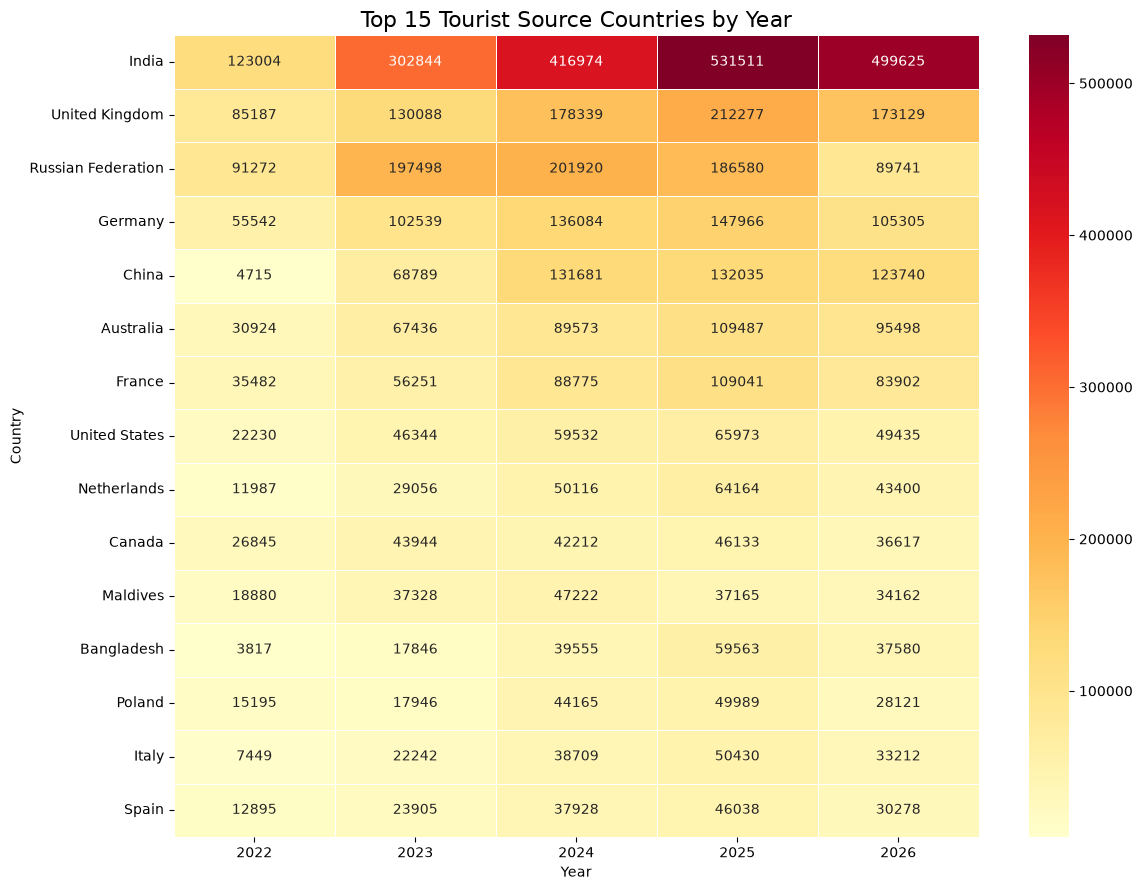

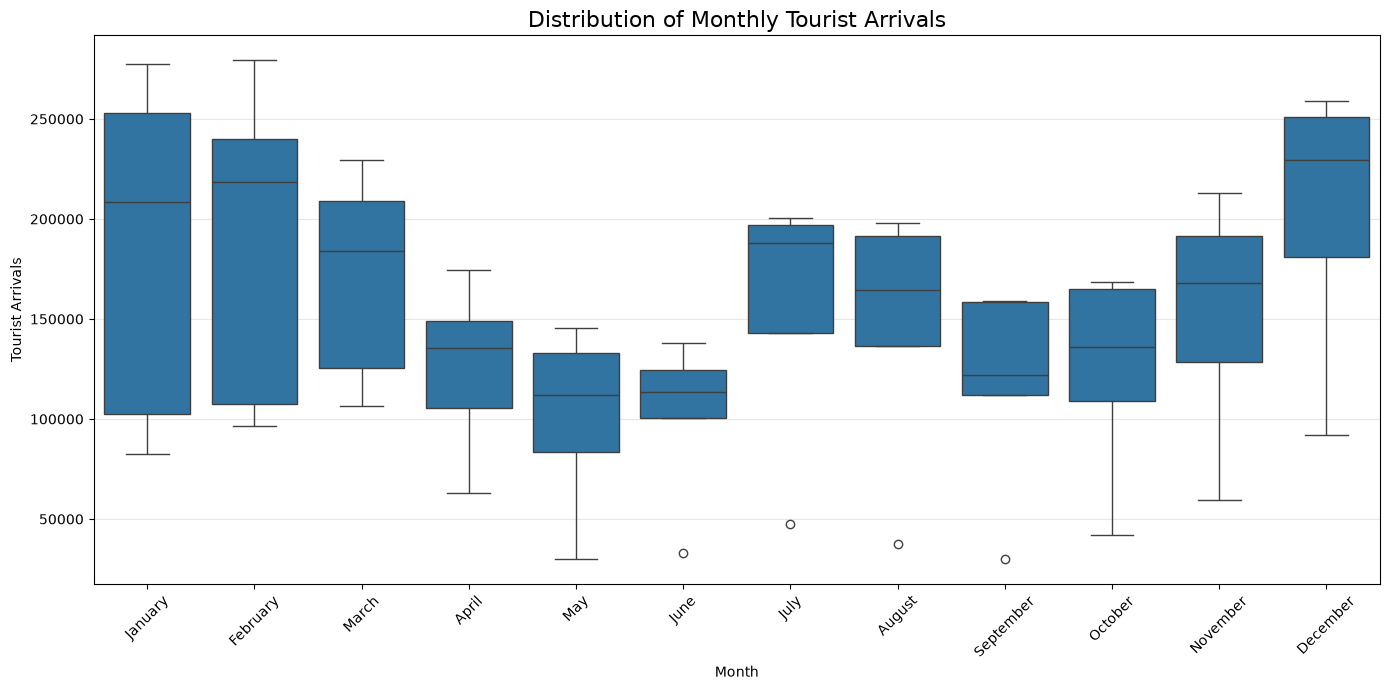

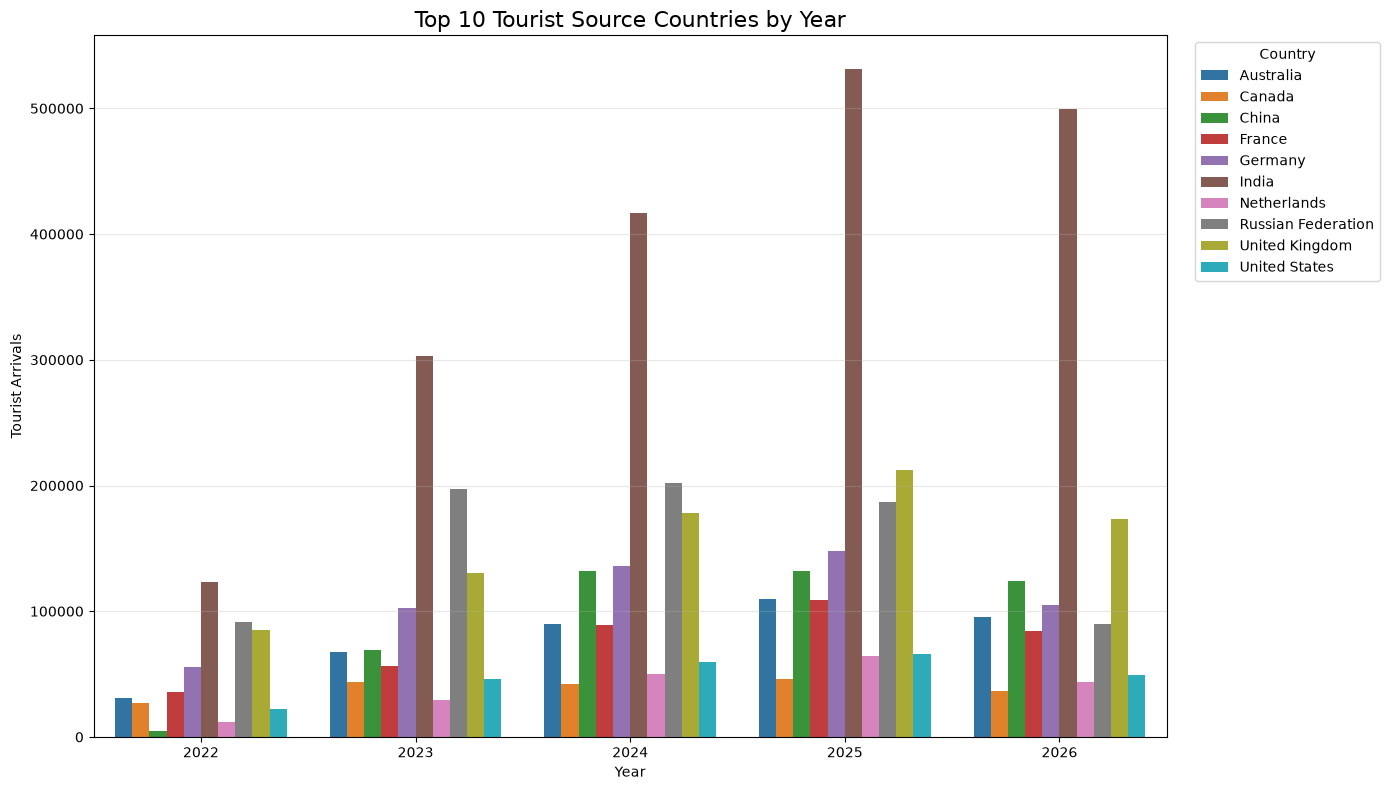



VISUALIZATION COMPLETED SUCCESSFULLY

MATPLOTLIB:
  01_yearly_tourist_arrivals.png
  02_jan_oct_comparison.png
  03_monthly_tourist_arrivals.png
  04_tourism_seasonality.png
  05_top_15_source_countries.png
  06_top_10_country_share.png

SEABORN:
  07_year_month_heatmap.png
  08_top_15_country_year_heatmap.png
  09_monthly_distribution_boxplot.png
  10_top_10_countries_by_year.png

PLOTLY:
  11_interactive_monthly_trend.html
  12_interactive_top_15_countries.html
  13_interactive_yearly_arrivals.html
  14_interactive_country_year_trend.html

Total visualizations created: 14

Output locations:
MATPLOTLIB: c:\DataAnalyticsPortfolio\01_Projects\01_Sri_Lanka_Tourism_Analytics\visualizations\matplotlib
SEABORN: c:\DataAnalyticsPortfolio\01_Projects\01_Sri_Lanka_Tourism_Analytics\visualizations\seaborn
PLOTLY: c:\DataAnalyticsPortfolio\01_Projects\01_Sri_Lanka_Tourism_Analytics\visualizations\plotly

Important:
2026 = January-October only.
Use Jan-Oct comparison when comparing 2026 with pr

In [4]:
# ============================================================
# PROJECT 01 - SRI LANKA TOURISM ANALYTICS
# NOTEBOOK 04 - COMPLETE VISUALIZATION
# ============================================================
#
# Libraries:
#   Matplotlib
#   Seaborn
#   Plotly
#
# Total visualizations:
#   Matplotlib -> 6
#   Seaborn   -> 4
#   Plotly    -> 4
#
# IMPORTANT:
# 2026 contains January-October only.
# For fair year-to-year comparison, Jan-Oct is used.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path


# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MATPLOTLIB_DIR = PROJECT_ROOT / "visualizations" / "matplotlib"
SEABORN_DIR = PROJECT_ROOT / "visualizations" / "seaborn"
PLOTLY_DIR = PROJECT_ROOT / "visualizations" / "plotly"


# Create folders if they don't exist
MATPLOTLIB_DIR.mkdir(parents=True, exist_ok=True)
SEABORN_DIR.mkdir(parents=True, exist_ok=True)
PLOTLY_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. LOAD CLEAN DATA
# ============================================================

input_file = PROCESSED_DIR / "tourism_arrivals_clean.csv"

tourism = pd.read_csv(input_file)


# ============================================================
# 4. DATA TYPE PREPARATION
# ============================================================

tourism["Date"] = pd.to_datetime(
    tourism["Date"],
    errors="coerce"
)

tourism["Year"] = pd.to_numeric(
    tourism["Year"],
    errors="coerce"
).astype("Int64")

tourism["Month_Number"] = pd.to_numeric(
    tourism["Month_Number"],
    errors="coerce"
).astype("Int64")

tourism["Arrivals"] = pd.to_numeric(
    tourism["Arrivals"],
    errors="coerce"
)


# ============================================================
# 5. COUNTRY COLUMN
# ============================================================
#
# Your cleaned dataset contains:
#
# Country_Raw
# Country_Standardized
#
# We use Country_Standardized for analysis.
# If a standardized value is missing, Country_Raw is used.
# ============================================================

tourism["Country_Display"] = (
    tourism["Country_Standardized"]
    .fillna(tourism["Country_Raw"])
    .astype(str)
    .str.strip()
)


# ============================================================
# 6. BASIC INFORMATION
# ============================================================

print("=" * 75)
print("SRI LANKA TOURISM - COMPLETE VISUALIZATION")
print("=" * 75)

print("\nDataset loaded successfully!")

print("\nRows:", len(tourism))

print(
    "Columns:",
    tourism.columns.tolist()
)

print(
    "Unique countries:",
    tourism["Country_Display"].nunique()
)

print(
    "Years:",
    sorted(
        tourism["Year"]
        .dropna()
        .unique()
        .tolist()
    )
)

print(
    "Date range:",
    tourism["Date"].min().date(),
    "to",
    tourism["Date"].max().date()
)

print("\n2026 contains January-October only.")


# ============================================================
# 7. PREPARE YEARLY DATA
# ============================================================

yearly = (
    tourism
    .groupby("Year", as_index=False)["Arrivals"]
    .sum(min_count=1)
)

print("\nYearly arrivals:")
print(yearly)


# ============================================================
# 8. PREPARE JAN-OCT DATA
# ============================================================

jan_oct = (
    tourism[
        tourism["Month_Number"] <= 10
    ]
    .groupby(
        "Year",
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

print("\nJanuary-October comparison:")
print(jan_oct)


# ============================================================
# 9. PREPARE MONTHLY DATA
# ============================================================

monthly = (
    tourism
    .groupby(
        ["Date", "Year", "Month_Number", "Month"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

monthly = monthly.sort_values("Date")


# ============================================================
# 10. PREPARE COUNTRY DATA
# ============================================================

country_totals = (
    tourism
    .groupby(
        "Country_Display",
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
    .sort_values(
        "Arrivals",
        ascending=False
    )
)

top15 = country_totals.head(15)


# ============================================================
# 11. PREPARE SEASONALITY DATA
# ============================================================

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

seasonality = (
    tourism
    .groupby(
        ["Month_Number", "Month"],
        as_index=False
    )["Arrivals"]
    .mean()
    .sort_values("Month_Number")
)

seasonality["Month"] = pd.Categorical(
    seasonality["Month"],
    categories=month_order,
    ordered=True
)

seasonality = seasonality.sort_values(
    "Month_Number"
)


# ============================================================
# MATPLOTLIB
# ============================================================


# ============================================================
# 12. MATPLOTLIB - YEARLY ARRIVALS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    yearly["Year"],
    yearly["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Sri Lanka Tourist Arrivals by Year",
    fontsize=16
)

plt.xlabel("Year")

plt.ylabel("Tourist Arrivals")

plt.xticks(
    yearly["Year"]
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "01_yearly_tourist_arrivals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 13. MATPLOTLIB - JAN-OCT COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    jan_oct["Year"].astype(str),
    jan_oct["Arrivals"]
)

plt.title(
    "Sri Lanka Tourist Arrivals - January to October",
    fontsize=15
)

plt.xlabel("Year")

plt.ylabel("Tourist Arrivals")

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    jan_oct["Arrivals"]
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "02_jan_oct_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 14. MATPLOTLIB - MONTHLY TREND
# ============================================================

plt.figure(figsize=(15, 7))

plt.plot(
    monthly["Date"],
    monthly["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Tourist Arrivals in Sri Lanka",
    fontsize=16
)

plt.xlabel("Month")

plt.ylabel("Tourist Arrivals")

plt.grid(
    True,
    alpha=0.3
)

plt.xticks(
    monthly["Date"],
    monthly["Date"].dt.strftime("%b-%Y"),
    rotation=45
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "03_monthly_tourist_arrivals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 15. MATPLOTLIB - SEASONALITY
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    seasonality["Month"].astype(str),
    seasonality["Arrivals"],
    marker="o",
    linewidth=2
)

plt.title(
    "Average Monthly Tourist Arrivals - Seasonality",
    fontsize=16
)

plt.xlabel("Month")

plt.ylabel("Average Tourist Arrivals")

plt.xticks(
    rotation=45
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "04_tourism_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 16. MATPLOTLIB - TOP 15 SOURCE COUNTRIES
# ============================================================

top15_plot = (
    top15
    .sort_values("Arrivals")
)

plt.figure(figsize=(11, 8))

plt.barh(
    top15_plot["Country_Display"],
    top15_plot["Arrivals"]
)

plt.title(
    "Top 15 Tourist Source Countries",
    fontsize=16
)

plt.xlabel("Total Tourist Arrivals")

plt.ylabel("Country")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "05_top_15_source_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 17. MATPLOTLIB - TOP 10 COUNTRY SHARE
# ============================================================

top10 = (
    country_totals
    .head(10)
    .copy()
)

total_arrivals = (
    country_totals["Arrivals"]
    .sum()
)

top10["Share"] = (
    top10["Arrivals"] /
    total_arrivals *
    100
)

plt.figure(figsize=(12, 7))

bars = plt.bar(
    top10["Country_Display"],
    top10["Share"]
)

plt.title(
    "Top 10 Source Countries - Share of Total Arrivals",
    fontsize=15
)

plt.xlabel("Country")

plt.ylabel(
    "Share of Total Arrivals (%)"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    top10["Share"]
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    MATPLOTLIB_DIR / "06_top_10_country_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SEABORN
# ============================================================


# ============================================================
# 18. SEABORN - YEAR/MONTH HEATMAP
# ============================================================

heatmap_data = (
    monthly
    .pivot(
        index="Year",
        columns="Month_Number",
        values="Arrivals"
    )
)

heatmap_data = heatmap_data.reindex(
    columns=range(1, 13)
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Monthly Tourist Arrivals Heatmap",
    fontsize=16
)

plt.xlabel("Month Number")

plt.ylabel("Year")

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "07_year_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 19. SEABORN - TOP 15 COUNTRY/YEAR HEATMAP
# ============================================================

top15_names = (
    country_totals
    .head(15)["Country_Display"]
    .tolist()
)

country_year = (
    tourism[
        tourism["Country_Display"]
        .isin(top15_names)
    ]
    .groupby(
        ["Country_Display", "Year"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

country_year_heatmap = (
    country_year
    .pivot(
        index="Country_Display",
        columns="Year",
        values="Arrivals"
    )
)

country_year_heatmap = (
    country_year_heatmap
    .reindex(top15_names)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    country_year_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Top 15 Tourist Source Countries by Year",
    fontsize=16
)

plt.xlabel("Year")

plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "08_top_15_country_year_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 20. SEABORN - MONTHLY DISTRIBUTION BOXPLOT
# ============================================================

monthly_box = (
    tourism
    .groupby(
        ["Year", "Month"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

monthly_box["Month"] = pd.Categorical(
    monthly_box["Month"],
    categories=month_order,
    ordered=True
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=monthly_box,
    x="Month",
    y="Arrivals"
)

plt.title(
    "Distribution of Monthly Tourist Arrivals",
    fontsize=16
)

plt.xlabel("Month")

plt.ylabel("Tourist Arrivals")

plt.xticks(
    rotation=45
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "09_monthly_distribution_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 21. SEABORN - TOP 10 COUNTRIES BY YEAR
# ============================================================

top10_names = (
    country_totals
    .head(10)["Country_Display"]
    .tolist()
)

top10_year = (
    tourism[
        tourism["Country_Display"]
        .isin(top10_names)
    ]
    .groupby(
        ["Year", "Country_Display"],
        as_index=False
    )["Arrivals"]
    .sum(min_count=1)
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=top10_year,
    x="Year",
    y="Arrivals",
    hue="Country_Display"
)

plt.title(
    "Top 10 Tourist Source Countries by Year",
    fontsize=16
)

plt.xlabel("Year")

plt.ylabel("Tourist Arrivals")

plt.legend(
    title="Country",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    SEABORN_DIR / "10_top_10_countries_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOTLY
# ============================================================


# ============================================================
# 22. PLOTLY - INTERACTIVE MONTHLY TREND
# ============================================================

fig = px.line(
    monthly,
    x="Date",
    y="Arrivals",
    markers=True,
    title="Interactive Monthly Tourist Arrivals - Sri Lanka",
    labels={
        "Date": "Month",
        "Arrivals": "Tourist Arrivals"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.write_html(
    PLOTLY_DIR /
    "11_interactive_monthly_trend.html"
)

fig.show()


# ============================================================
# 23. PLOTLY - INTERACTIVE TOP 15 COUNTRIES
# ============================================================

plotly_top15 = (
    country_totals
    .head(15)
    .sort_values("Arrivals")
)

fig = px.bar(
    plotly_top15,
    x="Arrivals",
    y="Country_Display",
    orientation="h",
    title="Interactive Top 15 Tourist Source Countries",
    labels={
        "Arrivals": "Total Tourist Arrivals",
        "Country_Display": "Country"
    }
)

fig.update_layout(
    template="plotly_white"
)

fig.write_html(
    PLOTLY_DIR /
    "12_interactive_top_15_countries.html"
)

fig.show()


# ============================================================
# 24. PLOTLY - INTERACTIVE YEARLY ARRIVALS
# ============================================================

fig = px.bar(
    yearly,
    x="Year",
    y="Arrivals",
    text="Arrivals",
    title="Interactive Sri Lanka Tourist Arrivals by Year",
    labels={
        "Year": "Year",
        "Arrivals": "Tourist Arrivals"
    }
)

fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white"
)

fig.write_html(
    PLOTLY_DIR /
    "13_interactive_yearly_arrivals.html"
)

fig.show()


# ============================================================
# 25. PLOTLY - COUNTRY/YEAR TREND
# ============================================================

fig = px.line(
    country_year,
    x="Year",
    y="Arrivals",
    color="Country_Display",
    markers=True,
    title="Interactive Tourist Arrivals by Major Source Country",
    labels={
        "Year": "Year",
        "Arrivals": "Tourist Arrivals",
        "Country_Display": "Country"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.write_html(
    PLOTLY_DIR /
    "14_interactive_country_year_trend.html"
)

fig.show()


# ============================================================
# 26. FINAL REPORT
# ============================================================

print("\n")
print("=" * 75)
print("VISUALIZATION COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nMATPLOTLIB:")
print("  01_yearly_tourist_arrivals.png")
print("  02_jan_oct_comparison.png")
print("  03_monthly_tourist_arrivals.png")
print("  04_tourism_seasonality.png")
print("  05_top_15_source_countries.png")
print("  06_top_10_country_share.png")

print("\nSEABORN:")
print("  07_year_month_heatmap.png")
print("  08_top_15_country_year_heatmap.png")
print("  09_monthly_distribution_boxplot.png")
print("  10_top_10_countries_by_year.png")

print("\nPLOTLY:")
print("  11_interactive_monthly_trend.html")
print("  12_interactive_top_15_countries.html")
print("  13_interactive_yearly_arrivals.html")
print("  14_interactive_country_year_trend.html")

print("\nTotal visualizations created: 14")

print("\nOutput locations:")
print("MATPLOTLIB:", MATPLOTLIB_DIR)
print("SEABORN:", SEABORN_DIR)
print("PLOTLY:", PLOTLY_DIR)

print("\nImportant:")
print("2026 = January-October only.")
print("Use Jan-Oct comparison when comparing 2026 with previous years.")

print("=" * 75)